# Sanctions Name Screening project

## Project description:

Some text here about the project

Maybe some formulas 
$\frac{\sum}{\alpha}$

## Setup


In [8]:
import sys; print(sys.executable)

/opt/anaconda3/envs/IDS/bin/python


In [4]:
#imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from pathlib import Path

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

pairs_path = project_root / "data/interim/pairs_flat.parquet"
names_path = project_root / "data/interim/name_frequency.parquet"

pairs = pd.read_parquet(pairs_path)

print("Pairs dataset shape:", pairs.shape)


Pairs dataset shape: (755540, 32)
Names dataset shape: (1357827, 3)


---

# What this notebook does

We ask each question related to Exploratory Data Analysis in a heading and write code below that answers it.

**Part 3** produces the cleaned table that parts
4 to 7 use.

When a question produces a number that will end up in the report, move that
code into `src/screening/` afterwards so it can be re-run. Notebooks explore,
scripts produce.

---

# 1. First look at the data

### 1.1 What shape is the data, and what does one row represent?

*Everything downstream depends on getting this sentence right. One row is one what?*

# `pairs`:

In [ ]:
pairs.head()

,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_country,right_country,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics
0,0,positive,eu-fsf-eu-3298-47,unsc-2894441,Person,Person,مثنى حارث سلمان الضاري,MUTHANNA HARITH SALMAN AL-DARI,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Abu Ghurayb, IRAQ, Khan Dari, I...","[Amman, Jordan, Asas Village, Iraq, Khan Dari,...",[sanction],[sanction]
1,1,positive,ofac-11493,unsc-2894441,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, pl_finanse_sanctions, be_fod...",...,"[eg, jo, iq]","[iq, eg, jo]",[iq],[iq],[],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
2,2,positive,unsc-2894441,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",[ua_sfms_blacklist],...,"[iq, eg, jo]",[],[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Iraq, Asas Village, Abu Ghurayb...","[Amman, Jordan, Asas Village, Abu Ghurayb, Ira...",[sanction],[sanction]
3,3,positive,gb-hmt-11052,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,MUTHANNA HARITH SALMAN AL-DARI,Muthanna Harith AL-DARI,[gb_hmt_sanctions],"[un_sc_sanctions, us_ofac_sdn, pl_finanse_sanc...",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],[1729765],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
4,4,positive,eu-fsf-eu-2799-30,unsc-2971675,Person,Person,Abdurrahim Bashir,ABDUL RAHIM BA'AYSIR,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[in, id]",[id],[id],[id],[],[],[],[],[sanction],[sanction]


> The grain of `pairs` dataset is `pair_id` which represents the unique identifier of a pair of entities that an analyst reviewed after a generated potential match.

# `names`:

In [25]:
from collections import Counter

with open("data/raw/names.txt", encoding="utf-8", errors="ignore") as f:
    names = Counter(line.strip().casefold() for line in f if line.strip())

freq_names = pd.Series(names).sort_values(ascending=False)

print("Names frequency dataset shape:", freq_names.shape)
freq_names.head(20)

Names frequency dataset shape: (3152286,)


fasse                                   2
michael gross                           2
peter weiss                             2
albert dess                             2
heinz fassmann                          2
jennifer gross                          2
dieisme rederson cavatão                1
valmir josé de oliveira                 1
deoclides crispim corrêa filho          1
isadora zinnke                          1
maria madalena santana                  1
ednaldo coutinho vital                  1
edison damião de sousa                  1
maria eliete ferreira borges            1
eliane aparecida dos santos             1
gabriel henrique bento gonçalves        1
justiniano faustino dos santos filho    1
henrique cesar liria alves              1
idel sidney goncalves silveira          1
mayor, francinópolis-pi                 1
dtype: int64

> `freq_names` is a Series which counts the frequency of names appearing in pairs. The grain is the unique name. However:
> - Tokens tell us which name-parts are common, which is more valuable for matching

In [14]:
with open("data/raw/names.txt", encoding="utf-8", errors="ignore") as f:
    tokens = Counter(tok for line in f for tok in line.casefold().split())

freq_tokens = pd.Series(tokens).sort_values(ascending=False)
print("Tokens frequency dataset shape:", freq_tokens.shape)

freq_tokens.head()

Tokens frequency dataset shape: (1596879,)


of                  197203
общество             96537
с                    85910
ограниченной         75511
ответственностью     74938
dtype: int64

> `freq_tokens` grain is unique token that appears in the `names` dataset

### 1.2 What record types are in the file, and are they all the same problem?

*Decides what stays in scope. Some pair types may not be name comparisons at all.*

In [16]:
pairs.info()

<class 'pandas.DataFrame'>
RangeIndex: 755540 entries, 0 to 755539
Data columns (total 32 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   pair_id            755540 non-null  int64 
 1   judgement          755540 non-null  str   
 2   left_id            755540 non-null  str   
 3   right_id           755540 non-null  str   
 4   left_schema        755540 non-null  str   
 5   right_schema       755540 non-null  str   
 6   left_caption       755540 non-null  str   
 7   right_caption      755540 non-null  str   
 8   left_datasets      755540 non-null  object
 9   right_datasets     755540 non-null  object
 10  left_name          755540 non-null  object
 11  right_name         755540 non-null  object
 12  left_alias         755540 non-null  object
 13  right_alias        755540 non-null  object
 14  left_firstName     755540 non-null  object
 15  right_firstName    755540 non-null  object
 16  left_lastName      755540 non-n

Every entity property in this data is a **list of strings**, even when it holds a single value, because one record can carry several spellings of a name or several reported dates of birth. An absent field is an empty list, never a null. Code that assumes `value[0]` exists will fail on roughly half the rows for some fields.

| variable | meaning | unit | type | values/range | missing coding | role | status | notes/concerns |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| `pair_id` | the unique identifier of a pair of entities | - | integer `int64` | e.g. `1`, `2` | none present | **index** | keep | 
| `judgement` | analyst's decision about the pair | - | categorical `str` | `positive`, `negative` | none present | **target** | keep | documentation lists a third value, `unsure`, which does not occur in this file |
| `left_id` / `right_id` | OpenSanctions entity identifier | - | string `str`| e.g. `Q18224025`, `NK-aTXq...` | none present | identifier | keep, not a feature | 38,217 rows have the same id on both sides |
| `left_schema` / `right_schema` | kind of entity | - | categorical `str` | Person, Company, Organization, Occupancy, Succession, Position, ... | none present | filter + predictor | keep | used to scope the project to three types |
| `left_caption` / `right_caption` | display name | - | string `str` | 1-375 characters, median 23 | none present | main predictor source | keep | one of the names in `*_name`; using it alone discards the aliases |
| `left_name` / `right_name` | all name spellings | - | list of strings `object` | median 1 per entity, p90 12, max 293 | `[]`, 1.2% of pairs | predictor source | keep | comparing across full lists is more expensive but should beat caption-only |
| `left_alias` / `right_alias` | further alternative names | - | list of strings `object` | both sides present in 41.2% | `[]` | predictor source | keep | overlaps with `name`, needs de-duplicating |
| `left_birthDate` / `right_birthDate` | reported date(s) of birth | date | list of strings `object` | mixed precision: `1969`, `1969-06`, `1969-06-16` | `[]`, both sides present in 49.2% | strong predictor | keep | stored as text, not dates; 11.6% of entities carry more than one |
| `left_country` / `right_country` | associated countries | - | list of ISO-2 codes `object` | both sides present in 61.0% | `[]` | predictor | keep | agreement is weak evidence, disagreement is strong |
| `left_nationality` / `right_nationality` | nationality | - | list of ISO-2 codes `object` | both sides present in 15.9% | `[]` | predictor | keep with caution | too sparse to carry much weight |
| `left_idNumber` / `right_idNumber` | passport, tax, registration numbers | - | list of strings `object` | both sides present in 9.1% | `[]` | predictor | keep | decisive when present, almost never present |
| `left_firstName` / `left_lastName` / `left_middleName` | parsed name components | - | list of strings `object` | both sides present in 40-45% | `[]` | predictor | keep | parsing quality varies by source list |
| `left_address` / `right_address` | addresses | - | list of free text `object` | both sides present in 42.7% | `[]` | probably not used | park | unstructured; industry commentary blames free-text addresses for much of the false-positive problem, so it is interesting but out of scope for us |
| `left_topics` / `right_topics` | risk tags | - | list of strings `object` | `sanction`, `role.pep`, `crime.fin`, ... | `[]` | **excluded** | drop | describes the listing, not the identity |
| `left_datasets` / `right_datasets` | which source lists the record came from | - | list of strings `object` | 293 possible values | none present | **excluded, leaky** | drop | predicts the label at 92% accuracy on its own |

### 1.3 What does a single row actually contain?

*Look at one row in full. Note which fields are lists rather than single values.*

In [17]:
pairs.iloc[1,:]

pair_id                                                              1
judgement                                                     positive
left_id                                                     ofac-11493
right_id                                                  unsc-2894441
left_schema                                                     Person
right_schema                                                    Person
left_caption                                   Muthanna Harith AL-DARI
right_caption                           MUTHANNA HARITH SALMAN AL-DARI
left_datasets                              [us_ofac_sdn, us_trade_csl]
right_datasets       [un_sc_sanctions, pl_finanse_sanctions, be_fod...
left_name            [Muthanna Harith AL-DARI, AL-DARI, Muthanna Ha...
right_name           [Muthanna Hareth al-Dari, Muthanna Harith Sula...
left_alias           [Muthanna Harith Sulayman AL-DARI, Muthana Har...
right_alias          [Muthanna Hareth al-Dari, Muthanna Harith Sula...
left_f

> One row represents characteristics of one entity

> Features, which are lists (or `objects`):

| feature that is a list | Dtype | 
|---|---|
| `left_datasets` |  `object`|
  | `right_datasets`|       `object`|
  |`left_name`   |         `object`|
  |`right_name`   |        `object`|
  |`left_alias`   |        `object`|
  |`right_alias`  |        `object`|
  |`left_firstName`|       `object`|
  |`right_firstName`|      `object`|
  |`left_lastName`  |      `object`|
 | `right_lastName`   |    `object`|
 | `left_middleName` |     `object`|
 | `right_middleName` |    `object`|
  |`left_birthDate`  |     `object`|
| `right_birthDate` |    `object`|
  |`left_country`   |      `object`|
 | `right_country` |       `object`|
 | `left_nationality` |    `object`|
 | `right_nationality` |   `object`|
  |`left_idNumber`  |      `object`|
  |`right_idNumber` |    `object` |  
  |`left_address` |        `object`|
  |`right_address` |       `object`|
 |`left_topics` |        `object`|
 | `right_topics`  |      `object`|

### 1.4 Which columns describe the entities, and which describe how the data was made?

*Flag the second kind now; they come back in part 7.*

In [18]:
pairs.columns

Index(['pair_id', 'judgement', 'left_id', 'right_id', 'left_schema',
       'right_schema', 'left_caption', 'right_caption', 'left_datasets',
       'right_datasets', 'left_name', 'right_name', 'left_alias',
       'right_alias', 'left_firstName', 'right_firstName', 'left_lastName',
       'right_lastName', 'left_middleName', 'right_middleName',
       'left_birthDate', 'right_birthDate', 'left_country', 'right_country',
       'left_nationality', 'right_nationality', 'left_idNumber',
       'right_idNumber', 'left_address', 'right_address', 'left_topics',
       'right_topics'],
      dtype='str')

In [36]:
import pandas as pd
from pathlib import Path

df = pd.read_parquet(Path("data/interim/pairs_flat.parquet"))

ROLE = {
    "pair_id":     ("our own key", "row number we assigned at parse time"),
    "judgement":   ("TARGET",      "the analyst's decision; this is the label"),
    "id":          ("identifier",  "names the record, not the entity's properties"),
    "schema":      ("entity",      "what kind of thing it is"),
    "caption":     ("entity",      "display name"),
    "name":        ("entity",      "all name spellings"),
    "alias":       ("entity",      "further names"),
    "firstName":   ("entity",      "parsed name part"),
    "middleName":  ("entity",      "parsed name part"),
    "lastName":    ("entity",      "parsed name part"),
    "birthDate":   ("entity",      "when the person was born"),
    "country":     ("entity",      "associated country"),
    "nationality": ("entity",      "nationality"),
    "idNumber":    ("entity",      "passport / tax / registration number"),
    "address":     ("entity",      "where they are"),
    "topics":      ("PROCESS",     "why the entity was listed, not who it is"),
    "datasets":    ("PROCESS",     "which source lists the record came from"),
}

rows = []
for col in df.columns:
    base = col.removeprefix("left_").removeprefix("right_")
    role, why = ROLE.get(base, ("?", "unclassified - look at it"))
    rows.append({"column": col, "base": base, "role": role, "why": why})

cols = pd.DataFrame(rows)

print(f"{len(df.columns)} columns, {cols.base.nunique()} distinct fields\n")
print(cols.drop_duplicates("base").role.value_counts().to_string())

print("\n--- columns that describe HOW THE DATA WAS MADE ---")
print(cols[cols.role == "PROCESS"][["column", "why"]].to_string(index=False))

print("\n--- identifiers: real, but never features ---")
print(cols[cols.role == "identifier"].column.tolist())

# Evidence, so the classification isn't just an assertion
print("\n`datasets` holds source-list names, nothing about the person:")
for c in df.left_datasets.head(4):
    print("   ", list(c))
print("\n`topics` holds listing reasons:")
for c in df.left_topics.head(4):
    print("   ", list(c))

32 columns, 17 distinct fields

role
entity         12
PROCESS         2
our own key     1
TARGET          1
identifier      1

--- columns that describe HOW THE DATA WAS MADE ---
        column                                      why
 left_datasets  which source lists the record came from
right_datasets  which source lists the record came from
   left_topics why the entity was listed, not who it is
  right_topics why the entity was listed, not who it is

--- identifiers: real, but never features ---
['left_id', 'right_id']

`datasets` holds source-list names, nothing about the person:
    ['eu_fsf', 'be_fod_sanctions']
    ['us_ofac_sdn', 'us_trade_csl']
    ['un_sc_sanctions', 'us_ofac_sdn', 'us_trade_csl', 'pl_finanse_sanctions', 'be_fod_sanctions', 'eu_fsf', 'tr_fcib']
    ['gb_hmt_sanctions']

`topics` holds listing reasons:
    ['sanction']
    ['sanction']
    ['sanction']
    ['sanction']


---

# 2. Can we trust the labels?

Before measuring anything, find out what is wrong with the labels themselves.

### 2.1 Are there pairs where a record is paired with itself?

*A record trivially matches itself. If these exist they are free correct answers and would inflate every score.*

In [19]:
self_pairs = pairs.left_id == pairs.right_id

print(f"Rows where left_id == right_id: {self_pairs.sum():,}"
      f"({100 * self_pairs.mean():.1f}% of {len(pairs):,})")

print("\nhow are they labelled?")
print(pairs.loc[self_pairs, "judgement"].value_counts().to_string())

print("\nwhat kind of records?")
print(pairs.loc[self_pairs, "left_schema"].value_counts().to_string())

print("\nare the captions identical too?")
same_caption = pairs.loc[self_pairs, "left_caption"] == pairs.loc[self_pairs, "right_caption"]
print(f"    identical caption: {same_caption.sum():,} of {self_pairs.sum():,} ({100 * same_caption.mean():.1f}%)")

print("\nfive examples:")
print(pairs.loc[self_pairs, ["left_id", "left_caption", "judgement"]]
        .head().to_string(index=False))


Rows where left_id == right_id: 38,830(5.1% of 755,540)

how are they labelled?
judgement
positive    38819
negative       11

what kind of records?
left_schema
Person          21353
Company         13185
Organization     3679
Vessel            324
LegalEntity       186
Position           81
Succession         12
Directorship        8
Occupancy           2

are the captions identical too?
    identical caption: 38,830 of 38,830 (100.0%)

five examples:
                  left_id                                                                                        left_caption judgement
                Q18224025                                                                   Shurygin Vladislav Vladislavovich  positive
                  Q656303                                                                                   Yegor Kholmogorov  positive
                 Q4102526                                                                                    Timur Vainshtein  positive

- The contradiction worth capturing: **self-pairs labelled `negative`**:

- This simply cannot be true since pairs match in the list, while the analyst's decision was `negative`

In [23]:
contradictory_pairs = pairs[self_pairs & (pairs.judgement == 'negative')]
print(f"\nself-pairs labelled NEGATIVE: {len(contradictory_pairs)}")
print(contradictory_pairs[["left_id", "right_id", "left_caption", "right_caption", "left_schema", "right_schema"]].to_string(index=False))


self-pairs labelled NEGATIVE: 11
                  left_id                  right_id                                                    left_caption                                                   right_caption  left_schema right_schema
NK-fZsRd2x8JueqDMMTbAMva9 NK-fZsRd2x8JueqDMMTbAMva9 Товариство з обмеженою відповідальністю "М2М Телематика Рязань" Товариство з обмеженою відповідальністю "М2М Телематика Рязань"      Company      Company
NK-ckp9dmxoJiBSCBmgjiDrEp NK-ckp9dmxoJiBSCBmgjiDrEp             Акціонерне товариство "Дорожній центр впровадження"             Акціонерне товариство "Дорожній центр впровадження"      Company      Company
                  Q316974                   Q316974                                                MUTASSIM QADHAFI                                                MUTASSIM QADHAFI       Person       Person
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb                                                AL-QAIDA IN IRAQ                           

### 2.2 Are there duplicate pairs?

*Duplicates put identical examples in both train and test, so the test score partly measures memorisation.*

In [35]:
mask = pairs.duplicated(
    subset=["left_id", "right_id"],
    keep=False
)

# Get duplicated rows
duplicated_pairs = pairs[mask]

# Count
print("Duplicated rows:", len(duplicated_pairs))

# Display
display(duplicated_pairs.head(10))



Duplicated rows: 37480


,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_country,right_country,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics
10371,10371,negative,NK-kGjoxxDX8oWgFuHxjp7nZZ,NK-mvTWs3h2BcnnSiyGU5B6nf,Person,Person,Tong-chol KIM,KIM TONG CHOL,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, jp_mof_sanctions, ua_sfms_bl...",...,[na],[kp],[],[kp],[],[],"[34 Herbst Street, Windhoek]",[],[sanction],[sanction]
47431,47431,negative,NK-kGjoxxDX8oWgFuHxjp7nZZ,NK-mvTWs3h2BcnnSiyGU5B6nf,Person,Person,Kim Tong-Chol,KIM TONG CHOL,"[us_ofac_sdn, us_trade_csl, jp_mof_sanctions]","[un_sc_sanctions, jp_mof_sanctions, ua_sfms_bl...",...,[na],[kp],[],[kp],[],[],"[34 Herbst Street, Windhoek, Namibia, 34 Herbs...",[],[sanction],[sanction]
85731,85731,negative,NK-5BWrb99C8VZobe8sLkYCn7,NK-eWeNqbYq47vav64ec4YcYX,Organization,Organization,Cham Investment Group,CHAM HOLDING,[fr_tresor_gels_avoir],"[us_ofac_sdn, us_trade_csl]",...,[sy],[sy],[],[],[],[],[Filiale de Cham Holding (Sehanya Daraa Highwa...,"[Cham Holding Building, Daraa Highway, Sahnaya...",[sanction],[sanction]
85734,85734,negative,NK-5BWrb99C8VZobe8sLkYCn7,NK-eWeNqbYq47vav64ec4YcYX,Organization,Organization,Cham Investment Group,CHAM HOLDING,"[eu_fsf, fr_tresor_gels_avoir, be_fod_sanction...","[us_ofac_sdn, us_trade_csl]",...,[sy],[sy],[],[],[],[],"[Sehanya Daraa Highway, PO Box 9525, Filiale d...","[Cham Holding Building, Daraa Highway, Sahnaya...",[sanction],[sanction]
96838,96838,negative,NK-UNTddvMRmv3S93Zm72G3BU,NK-mCp2cn8gQWJV3Z8DcqdMtZ,Organization,Organization,"Товариство з обмеженою відповідальністю ""М2М Т...","Товариство з обмеженою відповідальністю ""М2М Т...",[ua_nsdc_sanctions],[ua_nsdc_sanctions],...,[],[],[],[],[],[],"[Російська Федерація, 426039, Удмуртська Респу...","[Російська Федерація, 344000, Ростовська обл.,...",[sanction],[sanction]
99178,99178,negative,NK-ckp9dmxoJiBSCBmgjiDrEp,NK-faKDQ7xzPQuULkrjbMpQ7P,Organization,Organization,"Акціонерне товариство ""Дорожній центр впровадж...","Акціонерне товариство ""Дорожній центр впровадж...",[ua_nsdc_sanctions],[ua_nsdc_sanctions],...,[],[],[],[],[],[],"[Російська Федерація, 344019, Ростовська обл.,...","[Російська Федерація, 454091, Челябінська обл....",[sanction],[sanction]
115861,115861,negative,NK-2vxYEUQzxVGnsobxJBeFwC,NK-fZsRd2x8JueqDMMTbAMva9,Organization,Organization,"Товариство з обмеженою відповідальністю ""М2М Т...","Товариство з обмеженою відповідальністю ""М2М Т...",[ua_nsdc_sanctions],[ua_nsdc_sanctions],...,[],[],[],[],[],[],"[Російська Федерація, 392000, Тамбовська обл.,...","[Російська Федерація, 390026, Рязанська обл., ...",[sanction],[sanction]
168230,168230,negative,NK-MxwjSeBCvuUa2vN6VBVCbg,Q124755251,Person,Person,Pavlo Ihorovych FILIPCHUK,Філіпчук Павло Ігорович,"[us_ofac_sdn, jp_mof_sanctions, au_dfat_sancti...",[wikidata],...,[ua],[],[ua],[],[],[],"[Україна, м. Золочів, 25 Zolina Street, Kakhov...",[],[sanction],[]
243108,243108,negative,NK-QDrfCnufdmguPWhyYyrCfx,NK-mP7f6NnzfS8fWMvFYW8Qbg,Company,Company,Alabuga Development OOO,Alabuga special economic zone (SEZ),"[us_ofac_sdn, permid, mc_fund_freezes, eu_sanc...","[us_ofac_sdn, permid, eu_sanctions_map, fr_tre...",...,[ru],[ru],[],[],[],[95427882],"[УЛ. Ш-2 (ОЭЗ АЛАБУГА ТЕР.) К. 4, РЕСПУБЛИКА Т...","[Promploshchadka Alabuga, ul. Sh-2, Korp. 4/1,...","[export.control, sanction]","[export.control, sanction]"
254619,254619,negative,NK-biDuafitKowYFc5BR3gvAf,NK-fjWkU8ugJuP9iDW5V2wcQc,Organization,Company,Chimmed Group,Obshchestvo S Ogranichennoi Otvetstvennostyu T...,"[us_ofac_sdn, us_trade_csl]","[us_ofac_sdn, ext_ru_egrul, permid, us_trade_csl]",...,[ru],[ru],[],[],[],[62112778],"[Runovskiy, D 11/13, Korp 2, Moscow, Kashirsko...","[Ш КАШИРСКОЕ Д. 3 К. 2 СТР. 4, Г.МОСКВА, 11523...","[export.control, sanction]",[sanction]


### 2.3 Do any repeated pairs disagree with each other on the label?

*If the same pair is labelled both ways, there is a ceiling on measurable accuracy that belongs to the labels, not the model.*

In [41]:
different_judgements = duplicated_pairs.groupby(["left_id", "right_id"]).filter(lambda x: len(x['judgement'].nunique()) > 1)

print(f"Distribution of judgement values in duplicated pairs: \n{duplicated_pairs['judgement'].value_counts().to_string(index=False)}")

print(f"\n Where the duplicated pairs have different judgements: \n{different_judgements[['left_id', 'right_id', 'judgement']].to_string(index=False)}")


TypeError: object of type 'int' has no len()

In [43]:
conflict_mask = (
    duplicated_pairs
    .groupby(["left_id", "right_id"])["judgement"]
    .transform("nunique") > 1
)

different_judgements = duplicated_pairs[conflict_mask]

print(different_judgements[["left_id", "right_id", "judgement"]].to_string(index=False))

                  left_id                  right_id judgement
NK-biDuafitKowYFc5BR3gvAf NK-fjWkU8ugJuP9iDW5V2wcQc  negative
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-nXLmzkpmQp96ZWujMYTamk NK-nXLmzkpmQp96ZWujMYTamk  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
                  Q316974                   Q316974  negative
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  negative
            ch-seco-87527 NK-nXLmzkpmQp96ZWujMYTamk  negative
            ch-seco-87527 NK-nXLmzkpmQp96ZWujMYTamk  positive
NK-eDzfacajrYcoANnjiqUi7E NK-eDzfacajrYcoANnjiqUi7E  positive
NK-eDzfacajrYcoANnjiqUi7E NK-eDzfacajrYcoANnjiqUi7E  positive
NK-biDua

### 2.4 How often does the same entity appear across different pairs?

*Decides whether train/test can be split by row or must be split by entity.*

### 2.5 Are there missing or impossible values in the key columns?

*Nulls in ids, captions or the label. Negative or absurd values anywhere.*

---

# 3. Clean and prepare

Everything from here on uses the table this part produces. Write down the
reason for each decision in `docs/decisions.md` as you make it.

### 3.1 Apply the scope filter

*Keep only the record types that are genuinely name comparisons. Record why.*

### 3.2 Remove self-pairs and duplicates

*Keep a count of what each step removed; those numbers go in the report.*

### 3.3 What survived, and what is the label balance now?

*The balance will have moved. Report the cleaned figure, not the raw one.*

### 3.4 Save the cleaned table

*Write it to data/interim/. Everything below reads this file, so nobody re-derives it differently.*

---

# 4. What can we actually compute?

A feature needs its field present on **both** sides of a pair to be
computable for that pair. This part decides which features are even possible.

### 4.1 How often is each field present on both sides?

*The ceiling on every feature you might build.*

### 4.2 Does field presence differ between the two classes?

*If it does, missingness is itself a signal. Decide whether that is legitimate or leakage.*

### 4.3 What form do birth dates take?

*Check precision and whether one record can carry several. Decides whether date agreement is a boolean or a multi-level category.*

### 4.4 How many names does one entity carry?

*Decides whether to compare captions only or across the full alias lists.*

### 4.5 Is comparing across alias lists worth the extra cost?

*Measure it before building it. More spellings means more chances of a coincidental match too.*

---

# 5. Where is the difficulty?

This is the part that produces the findings worth presenting.

### 5.1 How well does a simple name-similarity score separate the two classes?

*Plot both distributions on the same axes. The region where they overlap is the whole problem.*

### 5.2 Are there pairs with identical names that are different entities?

*If so, no string metric can ever separate them. Check whether any other field can.*

### 5.3 Are company and organisation pairs different from person pairs?

*Company names carry legal suffixes shared by unrelated firms. Check whether the two behave the same.*

### 5.4 What happens on pairs written in two different alphabets?

*Measure the score's behaviour there rather than assuming. Then test whether simple normalisation helps.*

### 5.5 Does how common a name is relate to difficulty?

*Use names.txt for frequency. This is what the second dataset is for; confirm it earns its place.*

- A plain histogram is useless here — the distribution is so skewed that everything lands in the first bin. Hence, 3 that do work:

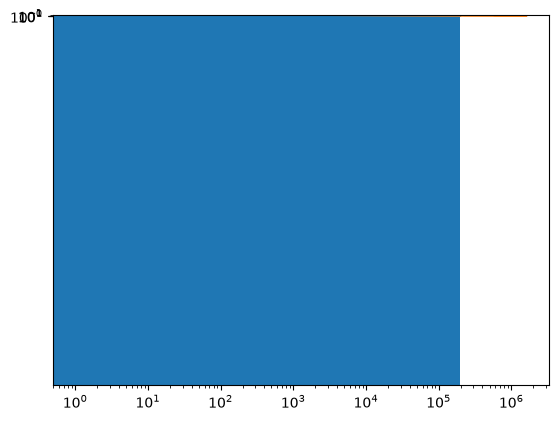

In [15]:
freq_tokens.head(30).plot.barh()              # the commonest, most legible view

freq_tokens.value_counts().sort_index().plot(loglog=True)   # how many tokens occur n times

# Zipf: rank against frequency, log-log. Should be close to a straight line.
plt.loglog(range(1, len(freq_tokens)+1), freq_tokens.values)

---

# 6. Is this one problem or two?

### 6.1 Split everything by whether a birth date exists on both sides

*Recompute the balance, the score distributions and the difficulty separately for each half.*

### 6.2 If one half is harder, is that the metric's fault or the data's?

*Try several different string metrics on the same split. If they all agree, it is the data.*

### 6.3 Decide: one model or two?

*Write the decision and the reason. This shapes steps 4 and 5 of the project.*

---

# 7. Leakage check

The last thing before feature engineering, and the easiest to skip. Some
columns describe how the dataset was assembled rather than who the entities
are. A model given those looks excellent and means nothing.

### 7.1 Can anything predict the label without reading the names at all?

*Test each suspect column on its own. Watch for features that point the *wrong* way: they are just as predictive.*

### 7.2 Which candidates must be excluded, and which are borderline?

*For each one, say what mechanism makes it leaky. If you cannot explain the mechanism, you have not found a leak yet.*

---

# 8. Wrap up

### 8.1 Collect the decisions this notebook produced

*One line each: what was decided, and the number that decided it.*

### 8.2 Save the final prepared dataset and note what step 4 needs from it

*Feature engineering starts from here.*

---
---

# Appendix: earlier work

Nothing here is deleted. As you redo a piece of analysis under its proper
question above, delete it from the appendix.

## A1. Earlier exploration

In [6]:
display(df.head(10))

df.info()

print(df.columns.tolist())

,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_country,right_country,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics
0,0,positive,eu-fsf-eu-3298-47,unsc-2894441,Person,Person,مثنى حارث سلمان الضاري,MUTHANNA HARITH SALMAN AL-DARI,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Abu Ghurayb, IRAQ, Khan Dari, I...","[Amman, Jordan, Asas Village, Iraq, Khan Dari,...",[sanction],[sanction]
1,1,positive,ofac-11493,unsc-2894441,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, pl_finanse_sanctions, be_fod...",...,"[eg, jo, iq]","[iq, eg, jo]",[iq],[iq],[],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
2,2,positive,unsc-2894441,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",[ua_sfms_blacklist],...,"[iq, eg, jo]",[],[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Iraq, Asas Village, Abu Ghurayb...","[Amman, Jordan, Asas Village, Abu Ghurayb, Ira...",[sanction],[sanction]
3,3,positive,gb-hmt-11052,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,MUTHANNA HARITH SALMAN AL-DARI,Muthanna Harith AL-DARI,[gb_hmt_sanctions],"[un_sc_sanctions, us_ofac_sdn, pl_finanse_sanc...",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],[1729765],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
4,4,positive,eu-fsf-eu-2799-30,unsc-2971675,Person,Person,Abdurrahim Bashir,ABDUL RAHIM BA'AYSIR,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[in, id]",[id],[id],[id],[],[],[],[],[sanction],[sanction]
5,5,positive,unsc-2971675,NK-QK52tZGY6r4uduAtCYCfWR,Person,Person,ABDUL RAHIM BA'AYSIR,Abdul Rahim BA'ASYIR,"[un_sc_sanctions, pl_finanse_sanctions, be_fod...","[us_ofac_sdn, us_trade_csl]",...,"[in, id]",[],[id],[id],[],[],[],[],[sanction],[sanction]
6,6,positive,ua-sfms-1132,NK-QK52tZGY6r4uduAtCYCfWR,Person,Person,ABDUL RAHIM BA'AYSIR,Abdul Rahim BA'ASYIR,[ua_sfms_blacklist],"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",...,[],"[in, id]",[id],[id],[],[],[],[],[sanction],[sanction]
7,7,positive,gb-hmt-10929,unsc-6908032,Person,Person,Yasin Ali Baynah,Yasin Ali Baynah,[gb_hmt_sanctions],[un_sc_sanctions],...,"[se, so]","[se, so]","[se, so]","[se, so]",[],[],"[Stockholm, Rinkeby, Mogadishu]","[Rinkeby, Stockholm, Sweden, Mogadishu, Somalia]",[sanction],[sanction]
8,8,positive,ua-sfms-1079,unsc-6908032,Person,Person,Yasin Ali Baynah,Yasin Ali Baynah,[ua_sfms_blacklist],"[un_sc_sanctions, gb_hmt_sanctions]",...,[],"[se, so]","[se, so]","[se, so]",[],[],[],"[Rinkeby, Stockholm, Sweden, Stockholm, Rinkeb...",[sanction],[sanction]
9,9,positive,eu-fsf-eu-3802-38,unsc-6908429,Organization,LegalEntity,Jabhat Fath al-Sham,AL-NUSRAH FRONT FOR THE PEOPLE OF THE LEVANT,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,[],"[iq, sy]",[],[],[],[],[],[],[sanction],[sanction]


<class 'pandas.DataFrame'>
RangeIndex: 755540 entries, 0 to 755539
Data columns (total 32 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   pair_id            755540 non-null  int64 
 1   judgement          755540 non-null  str   
 2   left_id            755540 non-null  str   
 3   right_id           755540 non-null  str   
 4   left_schema        755540 non-null  str   
 5   right_schema       755540 non-null  str   
 6   left_caption       755540 non-null  str   
 7   right_caption      755540 non-null  str   
 8   left_datasets      755540 non-null  object
 9   right_datasets     755540 non-null  object
 10  left_name          755540 non-null  object
 11  right_name         755540 non-null  object
 12  left_alias         755540 non-null  object
 13  right_alias        755540 non-null  object
 14  left_firstName     755540 non-null  object
 15  right_firstName    755540 non-null  object
 16  left_lastName      755540 non-n

In [7]:
df.isna().sum

<bound method DataFrame.sum of         pair_id  judgement  left_id  right_id  left_schema  right_schema  \
0         False      False    False     False        False         False   
1         False      False    False     False        False         False   
2         False      False    False     False        False         False   
3         False      False    False     False        False         False   
4         False      False    False     False        False         False   
...         ...        ...      ...       ...          ...           ...   
755535    False      False    False     False        False         False   
755536    False      False    False     False        False         False   
755537    False      False    False     False        False         False   
755538    False      False    False     False        False         False   
755539    False      False    False     False        False         False   

        left_caption  right_caption  left_datasets  righ

In [8]:
df["judgement"].value_counts()

df['left_schema'].value_counts()

left_schema
Person            285370
Occupancy         213448
Company            94204
Organization       62480
Succession         33607
Position           26330
LegalEntity        22779
Vessel              7550
Ownership           2392
Family              2301
Directorship        2099
Security            1661
CryptoWallet         818
UnknownLink          395
Airplane              84
Representation         7
Documentation          6
PublicBody             4
Employment             4
Associate              1
Name: count, dtype: int64

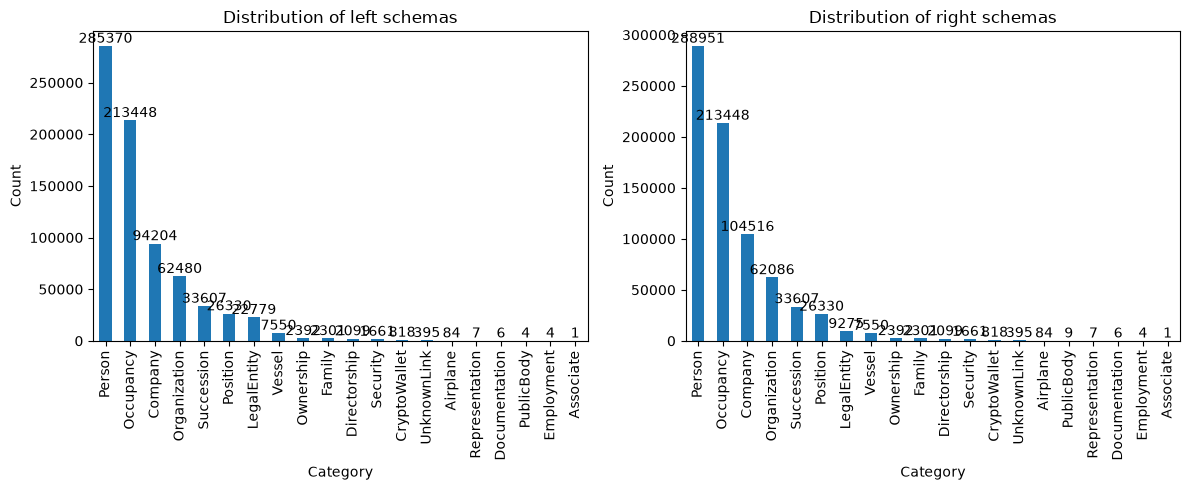

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left schema
df['left_schema'].value_counts().plot(kind='bar', ax=axes[0])

axes[0].set(
    title='Distribution of left schemas',
    xlabel='Category',
    ylabel='Count'
)

axes[0].bar_label(axes[0].containers[0])

# Right schema
df['right_schema'].value_counts().plot(kind='bar', ax=axes[1])

axes[1].set(
    title='Distribution of right schemas',
    xlabel='Category',
    ylabel='Count'
)

axes[1].bar_label(axes[1].containers[0])

plt.tight_layout()
plt.show()

- We have discrepancies across schema categories, (`right_schema` and `left_schema`)

In [10]:
#or:

df.loc[
    df['left_schema'] != df['right_schema'],
    ['left_schema', 'right_schema']
].value_counts()

left_schema   right_schema
Organization  Company         25849
Company       Organization    21953
LegalEntity   Company          7738
              Organization     4648
              Person           3969
Company       LegalEntity      1314
Organization  LegalEntity      1071
Person        LegalEntity       466
Organization  Person            123
Person        Organization       52
Company       Person             51
Person        Company            44
Organization  PublicBody          8
PublicBody    Organization        4
Company       PublicBody          1
Name: count, dtype: int64

In [11]:
df.loc[
    df['left_datasets'] != df['right_datasets'],
    ['left_datasets', 'right_datasets']
].value_counts()

ValueError: operands could not be broadcast together with shapes (2,) (3,) 

In [ ]:
df.loc[
    df['left_datasets'] == df['right_datasets'],
    ['left_datasets', 'right_datasets']
].value_counts()

ValueError: operands could not be broadcast together with shapes (2,) (3,) 

In [ ]:
df[['left_datasets','right_datasets']].head(20)

,left_datasets,right_datasets
0,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]"
1,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, pl_finanse_sanctions, be_fod..."
2,"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",[ua_sfms_blacklist]
3,[gb_hmt_sanctions],"[un_sc_sanctions, us_ofac_sdn, pl_finanse_sanc..."
4,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]"
5,"[un_sc_sanctions, pl_finanse_sanctions, be_fod...","[us_ofac_sdn, us_trade_csl]"
6,[ua_sfms_blacklist],"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p..."
7,[gb_hmt_sanctions],[un_sc_sanctions]
8,[ua_sfms_blacklist],"[un_sc_sanctions, gb_hmt_sanctions]"
9,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]"


# 2. Can we trust the labels?

## 2.1 Are there duplicate pairs?

1. Count duplicate ids on `right_id` and `left_id`

In [ ]:
df.loc[:,['right_id','left_id']]

,right_id,left_id
0,unsc-2894441,eu-fsf-eu-3298-47
1,unsc-2894441,ofac-11493
2,NK-6pe3A3UzgMBo5uQ6qEiUye,unsc-2894441
3,NK-6pe3A3UzgMBo5uQ6qEiUye,gb-hmt-11052
4,unsc-2971675,eu-fsf-eu-2799-30
...,...,...
755535,NK-i5HsmnwhdAZi7crpRMxuDm,NK-i5HsmnwhdAZi7crpRMxuDm
755536,pk-cnic-3240347507563,pk-cnic-3230415852241
755537,pk-cnic-3240347507563,pk-cnic-1730158775611
755538,pk-cnic-3240347507563,pk-cnic-1310108475041


In [ ]:
df.loc[
    df['right_id']==df['left_id'],
    ['right_id','left_id']
].value_counts()

right_id                   left_id                  
Q461631                    Q461631                      139
NK-neZdRCM4Agd9EjZvWy6Yoh  NK-neZdRCM4Agd9EjZvWy6Yoh    116
NK-mP2Qn89PXjHnin8ak9uPRb  NK-mP2Qn89PXjHnin8ak9uPRb     82
NK-nKeChvrHv8EX89KPe5kqbS  NK-nKeChvrHv8EX89KPe5kqbS     78
NK-digzwW9htWqm3jms86JLj7  NK-digzwW9htWqm3jms86JLj7     67
                                                       ... 
NK-MFEra9qNJu8eEDkpHu8R5A  NK-MFEra9qNJu8eEDkpHu8R5A      1
NK-DBTXP8rVUmiS5dssSsMN5x  NK-DBTXP8rVUmiS5dssSsMN5x      1
Q6580625                   Q6580625                       1
Q4364752                   Q4364752                       1
NK-i5HsmnwhdAZi7crpRMxuDm  NK-i5HsmnwhdAZi7crpRMxuDm      1
Name: count, Length: 9560, dtype: int64

In [ ]:
id_duplicates = df.loc[
    df['right_id']==df['left_id'],
    ['right_id']].count()

id_duplicates/df.count() * 100

judgement                 NaN
left_address              NaN
left_alias                NaN
left_birthDate            NaN
left_caption              NaN
left_country              NaN
left_datasets             NaN
left_firstName            NaN
left_id                   NaN
left_idNumber             NaN
left_lastName             NaN
left_middleName           NaN
left_name                 NaN
left_nationality          NaN
left_schema               NaN
left_topics               NaN
pair_id                   NaN
right_address             NaN
right_alias               NaN
right_birthDate           NaN
right_caption             NaN
right_country             NaN
right_datasets            NaN
right_firstName           NaN
right_id             5.139371
right_idNumber            NaN
right_lastName            NaN
right_middleName          NaN
right_name                NaN
right_nationality         NaN
right_schema              NaN
right_topics              NaN
dtype: float64

## A2. Draft kept from HW07

# Draft from HW07 (just to save it here)

In [13]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FLAT = ROOT / "data" / "interim" / "pairs_flat.parquet"

pairs = pd.read_parquet(FLAT)
print(f"rows: {len(pairs):,}   columns: {pairs.shape[1]}")

IN_SCOPE = ("Person", "Company", "Organization")
scoped = pairs[
    pairs.left_schema.isin(IN_SCOPE) & pairs.right_schema.isin(IN_SCOPE)
].copy()
print(f"in scope (both sides a name-bearing entity): {len(scoped):,}")
print()

print("record types, all rows:")
print((pairs.left_schema + " / " + pairs.right_schema).value_counts().head(8))
print()
print("one row looks like this:")
cols = ["judgement", "left_caption", "right_caption", "left_schema", "left_birthDate"]
print(scoped[cols].iloc[0].to_string())

rows: 755,540   columns: 32
in scope (both sides a name-bearing entity): 439,194

record types, all rows:
Person / Person                284808
Occupancy / Occupancy          213448
Company / Company               70885
Organization / Organization     35429
Succession / Succession         33607
Position / Position             26330
Organization / Company          25849
Company / Organization          21953
Name: count, dtype: int64

one row looks like this:
judgement                               positive
left_caption              مثنى حارث سلمان الضاري
right_caption     MUTHANNA HARITH SALMAN AL-DARI
left_schema                               Person
left_birthDate                [1969, 1969-06-16]


**b. Take a look at the data dictionaries or metadata to understand the meaning of each variable.**

Make sure to differenciate between technical type and meaning (integers for categorical, strings for dates, etc).

Find out the allowed values or range for each variable, check how categories are coded, and missing values represented. Think of the role of the variable in the project (target, candidate predictor, identifier, date/time, or not relevant).

If you can, try to find where the documentation and the data disagree.

You can do this as a text paragraph, a list, or as a table suggested below.


In [14]:
PROPS = ["name", "alias", "firstName", "lastName", "birthDate",
         "country", "nationality", "idNumber", "address", "topics"]

presence = pd.DataFrame([
    {
        "field": f,
        "left_present_%": round(100 * (scoped[f"left_{f}"].map(len) > 0).mean(), 1),
        "right_present_%": round(100 * (scoped[f"right_{f}"].map(len) > 0).mean(), 1),
        "both_present_%": round(100 * (
            (scoped[f"left_{f}"].map(len) > 0) & (scoped[f"right_{f}"].map(len) > 0)
        ).mean(), 1),
    }
    for f in PROPS
]).sort_values("both_present_%", ascending=False)
print("how often is each field usable, in-scope rows")
print(presence.to_string(index=False))
print()

lengths = [len(v) for lst in scoped.left_birthDate.head(200_000) for v in lst]
print("birthDate value lengths (4 = year only, 7 = year-month, 10 = full date):")
print(pd.Series(lengths).value_counts().to_dict())
print(f"entities carrying more than one birthDate: "
      f"{100 * (scoped.left_birthDate.map(len) > 1).mean():.1f}%")
print()
print("names held per entity: median %d, p90 %d, max %d" % (
    scoped.left_name.map(len).median(),
    scoped.left_name.map(len).quantile(0.9),
    scoped.left_name.map(len).max()))

how often is each field usable, in-scope rows
      field  left_present_%  right_present_%  both_present_%
       name           100.0             98.8            98.8
     topics            91.9             93.9            88.4
    country            76.2             75.1            61.0
  birthDate            50.6             57.2            49.2
  firstName            47.6             53.1            44.7
    address            49.1             53.6            42.7
      alias            49.5             59.6            41.2
   lastName            45.0             49.6            40.8
nationality            28.2             25.2            15.9
   idNumber            15.1             16.1             9.1

birthDate value lengths (4 = year only, 7 = year-month, 10 = full date):
{10: 115415, 4: 24273, 7: 712}
entities carrying more than one birthDate: 11.6%

names held per entity: median 1, p90 12, max 293


**c. First shots at visualizing the data**

Take a look at the data as plots to get more insight to the patterns, trends, and relationships. This could be histograms, scatter plots, box plots, ect. What did you gather? What stands out?

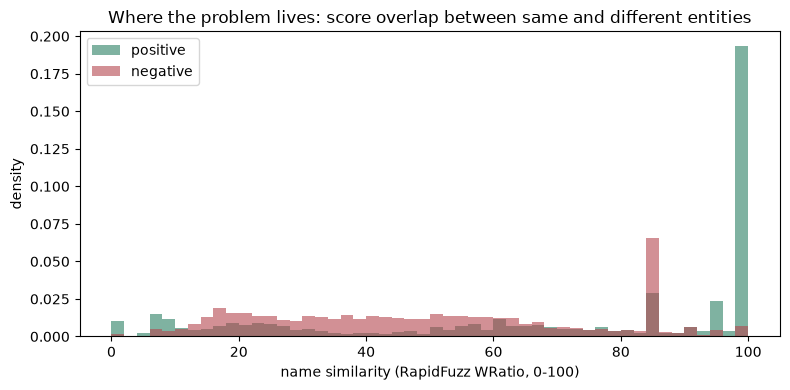

            25%   50%    75%
judgement                   
negative   27.9  48.0   69.1
positive   42.8  85.5  100.0

pairs scoring between 60 and 95, the ambiguous zone: 26.1%
different entities scoring a perfect 100: 1.36%


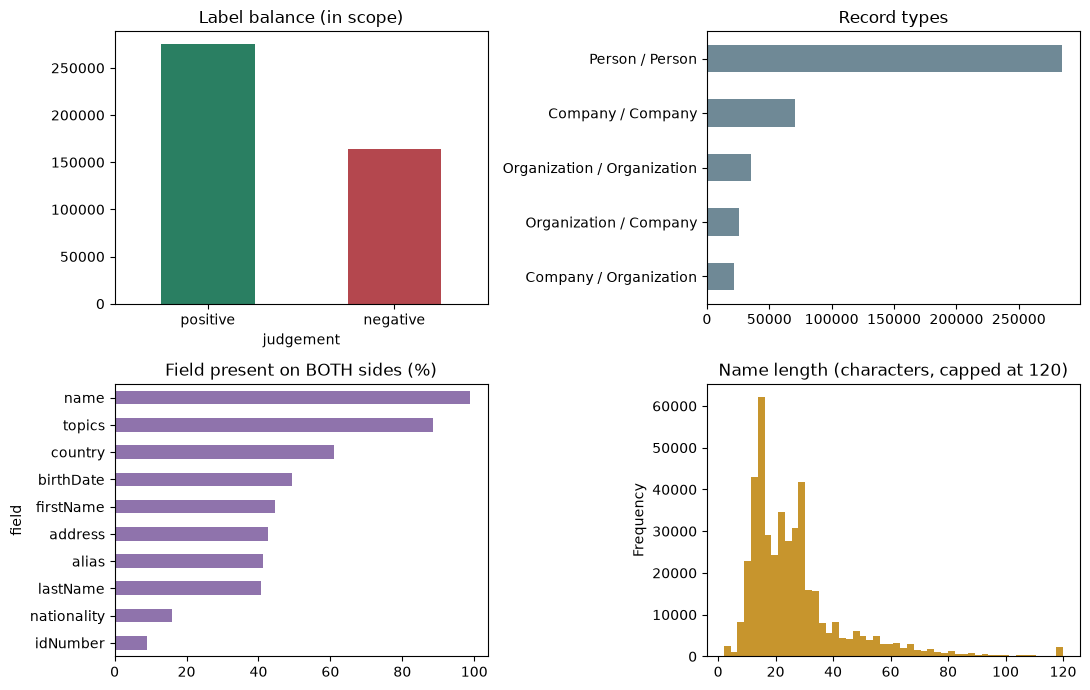

In [15]:
from rapidfuzz import fuzz

sample = scoped.sample(60_000, random_state=42).copy()
sample["sim"] = [fuzz.WRatio(a, b)
                 for a, b in zip(sample.left_caption, sample.right_caption)]

fig, ax = plt.subplots(figsize=(8, 4))
for label, colour in [("positive", "#2a7f62"), ("negative", "#b4474e")]:
    ax.hist(sample.loc[sample.judgement == label, "sim"],
            bins=50, alpha=0.6, density=True, label=label, color=colour)
ax.set_xlabel("name similarity (RapidFuzz WRatio, 0-100)")
ax.set_ylabel("density")
ax.set_title("Where the problem lives: score overlap between same and different entities")
ax.legend()
plt.tight_layout()
plt.show()

print(sample.groupby("judgement").sim.describe()[["25%", "50%", "75%"]].round(1))
print(f"\npairs scoring between 60 and 95, the ambiguous zone: "
      f"{100 * ((sample.sim > 60) & (sample.sim < 95)).mean():.1f}%")
print(f"different entities scoring a perfect 100: "
      f"{100 * (sample.loc[sample.judgement == 'negative', 'sim'] == 100).mean():.2f}%")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
scoped.judgement.value_counts().plot.bar(
    ax=axes[0, 0], color=["#2a7f62", "#b4474e"], rot=0, title="Label balance (in scope)")
(scoped.left_schema + " / " + scoped.right_schema).value_counts().head(5).plot.barh(
    ax=axes[0, 1], color="#6F8996", title="Record types")
axes[0, 1].invert_yaxis()
presence.set_index("field")["both_present_%"].plot.barh(
    ax=axes[1, 0], color="#8F73AC", title="Field present on BOTH sides (%)")
axes[1, 0].invert_yaxis()
scoped.left_caption.str.len().clip(upper=120).plot.hist(
    bins=50, ax=axes[1, 1], color="#C7952D", title="Name length (characters, capped at 120)")
plt.tight_layout()
plt.show()

**d. Check for data quality**

Missing values, duplicates, impossible or inconsistent values. Also watch out for outliers and anomalies that may require further investigation. Explain what you found and what you are going to do with the information.


In [16]:
print("=== duplicates and self-pairs ===")
self_pairs = scoped.left_id == scoped.right_id
print(f"an entity paired with itself : {int(self_pairs.sum()):,}")
print("  their labels:", scoped[self_pairs].judgement.value_counts().to_dict())

dups = scoped.duplicated(subset=["left_id", "right_id"], keep=False)
conflict = (scoped[dups].groupby(["left_id", "right_id"]).judgement.nunique() > 1).sum()
print(f"rows involved in repeated pairs: {int(dups.sum()):,}")
print(f"  repeated pairs labelled BOTH positive and negative: {int(conflict)}")

print("\n=== entity reuse (matters for the train/test split) ===")
appearances = pd.concat([scoped.left_id, scoped.right_id]).value_counts()
print(f"distinct entities: {len(appearances):,}")
print(f"appearances per entity: median {appearances.median():.0f}, "
      f"p99 {appearances.quantile(0.99):.0f}, max {appearances.max():,}")

print("\n=== missing and impossible values ===")
for col in ["judgement", "left_caption", "right_caption", "left_id", "right_id"]:
    print(f"  nulls in {col}: {int(scoped[col].isna().sum())}")

print("\n=== cleaning ===")
clean = (scoped[~self_pairs]
         .drop_duplicates(subset=["left_id", "right_id"])
         .reset_index(drop=True))
print(f"{len(pairs):,} raw  ->  {len(scoped):,} in scope  ->  {len(clean):,} after cleaning")
print("label balance after cleaning:",
      clean.judgement.value_counts(normalize=True).round(3).to_dict())

print("\n=== a feature that is too good to be true ===")
shared_source = clean.apply(
    lambda r: len(set(r.left_datasets) & set(r.right_datasets)) > 0, axis=1)
print(pd.crosstab(shared_source, clean.judgement, normalize="index").round(3))
rule = (~shared_source) == (clean.judgement == "positive")
print(f"accuracy of 'different source lists => same entity', using no names at all: "
      f"{100 * rule.mean():.1f}%")

print("\n=== identical names that are different entities ===")
identical = (clean.left_caption.str.strip().str.casefold()
             == clean.right_caption.str.strip().str.casefold())
print(f"negative pairs with identical names: "
      f"{int((identical & (clean.judgement == 'negative')).sum()):,}")

print("\n=== how far does birth date get us ===")
def birthdate_agreement(row):
    left, right = set(row.left_birthDate), set(row.right_birthDate)
    if not left or not right:
        return "missing on one side"
    if left & right:
        return "exact match"
    if {v[:4] for v in left} & {v[:4] for v in right}:
        return "same year only"
    return "conflict"

clean["bd"] = clean.apply(birthdate_agreement, axis=1)
print(pd.crosstab(clean.bd, clean.judgement, normalize="index").round(3))
print("\nrows in each group:", clean.bd.value_counts().to_dict())

=== duplicates and self-pairs ===
an entity paired with itself : 38,217
  their labels: {'positive': 38208, 'negative': 9}
rows involved in repeated pairs: 36,897
  repeated pairs labelled BOTH positive and negative: 8

=== entity reuse (matters for the train/test split) ===
distinct entities: 411,978
appearances per entity: median 1, p99 31, max 364

=== missing and impossible values ===
  nulls in judgement: 0
  nulls in left_caption: 0
  nulls in right_caption: 0
  nulls in left_id: 0
  nulls in right_id: 0

=== cleaning ===
755,540 raw  ->  439,194 in scope  ->  400,828 after cleaning
label balance after cleaning: {'positive': 0.591, 'negative': 0.409}

=== a feature that is too good to be true ===
judgement  negative  positive
row_0                        
False         0.050     0.950
True          0.882     0.118
accuracy of 'different source lists => same entity', using no names at all: 92.1%

=== identical names that are different entities ===
negative pairs with identical nam